# Daily weather lag correlations by station

This notebook correlates `water_level` with the 24-hour rolling weather features in the combined parquet dataset. The values are grouped by station and by daily offset (`0d` through `11d`). The results show that correlations of precipitation and relative humidity with water level is positive and decreases overtime. Correlation of temperature and pressure vapor are negative and increase over time.

In [8]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path("../../data/final/pegel_weather_6_hourly_lags12_days_weather_lags_forecast_72h.parquet")
OUT_DIR = Path("../out")
OUT_DIR.mkdir(parents=True, exist_ok=True)

COLUMN_PATTERN = re.compile(
    r"^(temperature_air_2m|precipitation_amount|humidity_relative|pressure_vapor)_"
    r"(\d{5})_rolling_24h_offset_(\d+)d$"
)

df = pd.read_parquet(DATA_PATH)
print(f"Loaded {len(df):,} rows and {len(df.columns):,} columns")
print(f"Time range: {df['timestamp'].min()} to {df['timestamp'].max()}")

Loaded 516,152 rows and 389 columns
Time range: 1968-01-01 00:00:00 to 2026-11-21 11:00:00


In [9]:
records = []
weather_columns = []

for column in df.columns:
    match = COLUMN_PATTERN.match(column)
    if match:
        weather_columns.append(column)
        variable, station_id, lag_days = match.groups()
        valid = df["water_level"].notna() & df[column].notna()
        records.append({
            "station_id": station_id,
            "variable": variable,
            "lag_days": int(lag_days),
            "correlation": df.loc[valid, "water_level"].corr(df.loc[valid, column]),
            "n_pairs": int(valid.sum()),
        })

correlations = pd.DataFrame(records)
station_ids = sorted(correlations["station_id"].unique())
variables = [
    "temperature_air_2m",
    "precipitation_amount",
    "humidity_relative",
    "pressure_vapor",
]

print(f"Matched {len(weather_columns)} daily weather lag columns across {len(station_ids)} stations")
print(f"Stations: {', '.join(station_ids)}")

strongest = (
    correlations.assign(abs_correlation=correlations["correlation"].abs())
    .sort_values(["station_id", "variable", "abs_correlation"], ascending=[True, True, False])
    .drop_duplicates(["station_id", "variable"])
    .sort_values(["station_id", "abs_correlation"], ascending=[True, False])
    .drop(columns="abs_correlation")
    .reset_index(drop=True)
)

strongest

Matched 240 daily weather lag columns across 5 stations
Stations: 02074, 03278, 03402, 04931, 06275


,station_id,variable,lag_days,correlation,n_pairs
0,02074,precipitation_amount,0,0.400008,193514
1,02074,temperature_air_2m,11,-0.340876,193292
2,02074,pressure_vapor,11,-0.311807,193292
3,02074,humidity_relative,0,0.258950,193292
4,03278,precipitation_amount,0,0.370219,199418
5,03278,temperature_air_2m,11,-0.341244,199267
6,03278,pressure_vapor,11,-0.304891,199267
7,03278,humidity_relative,0,0.245676,199267
8,03402,precipitation_amount,0,0.389875,208030
9,03402,temperature_air_2m,11,-0.353003,207833


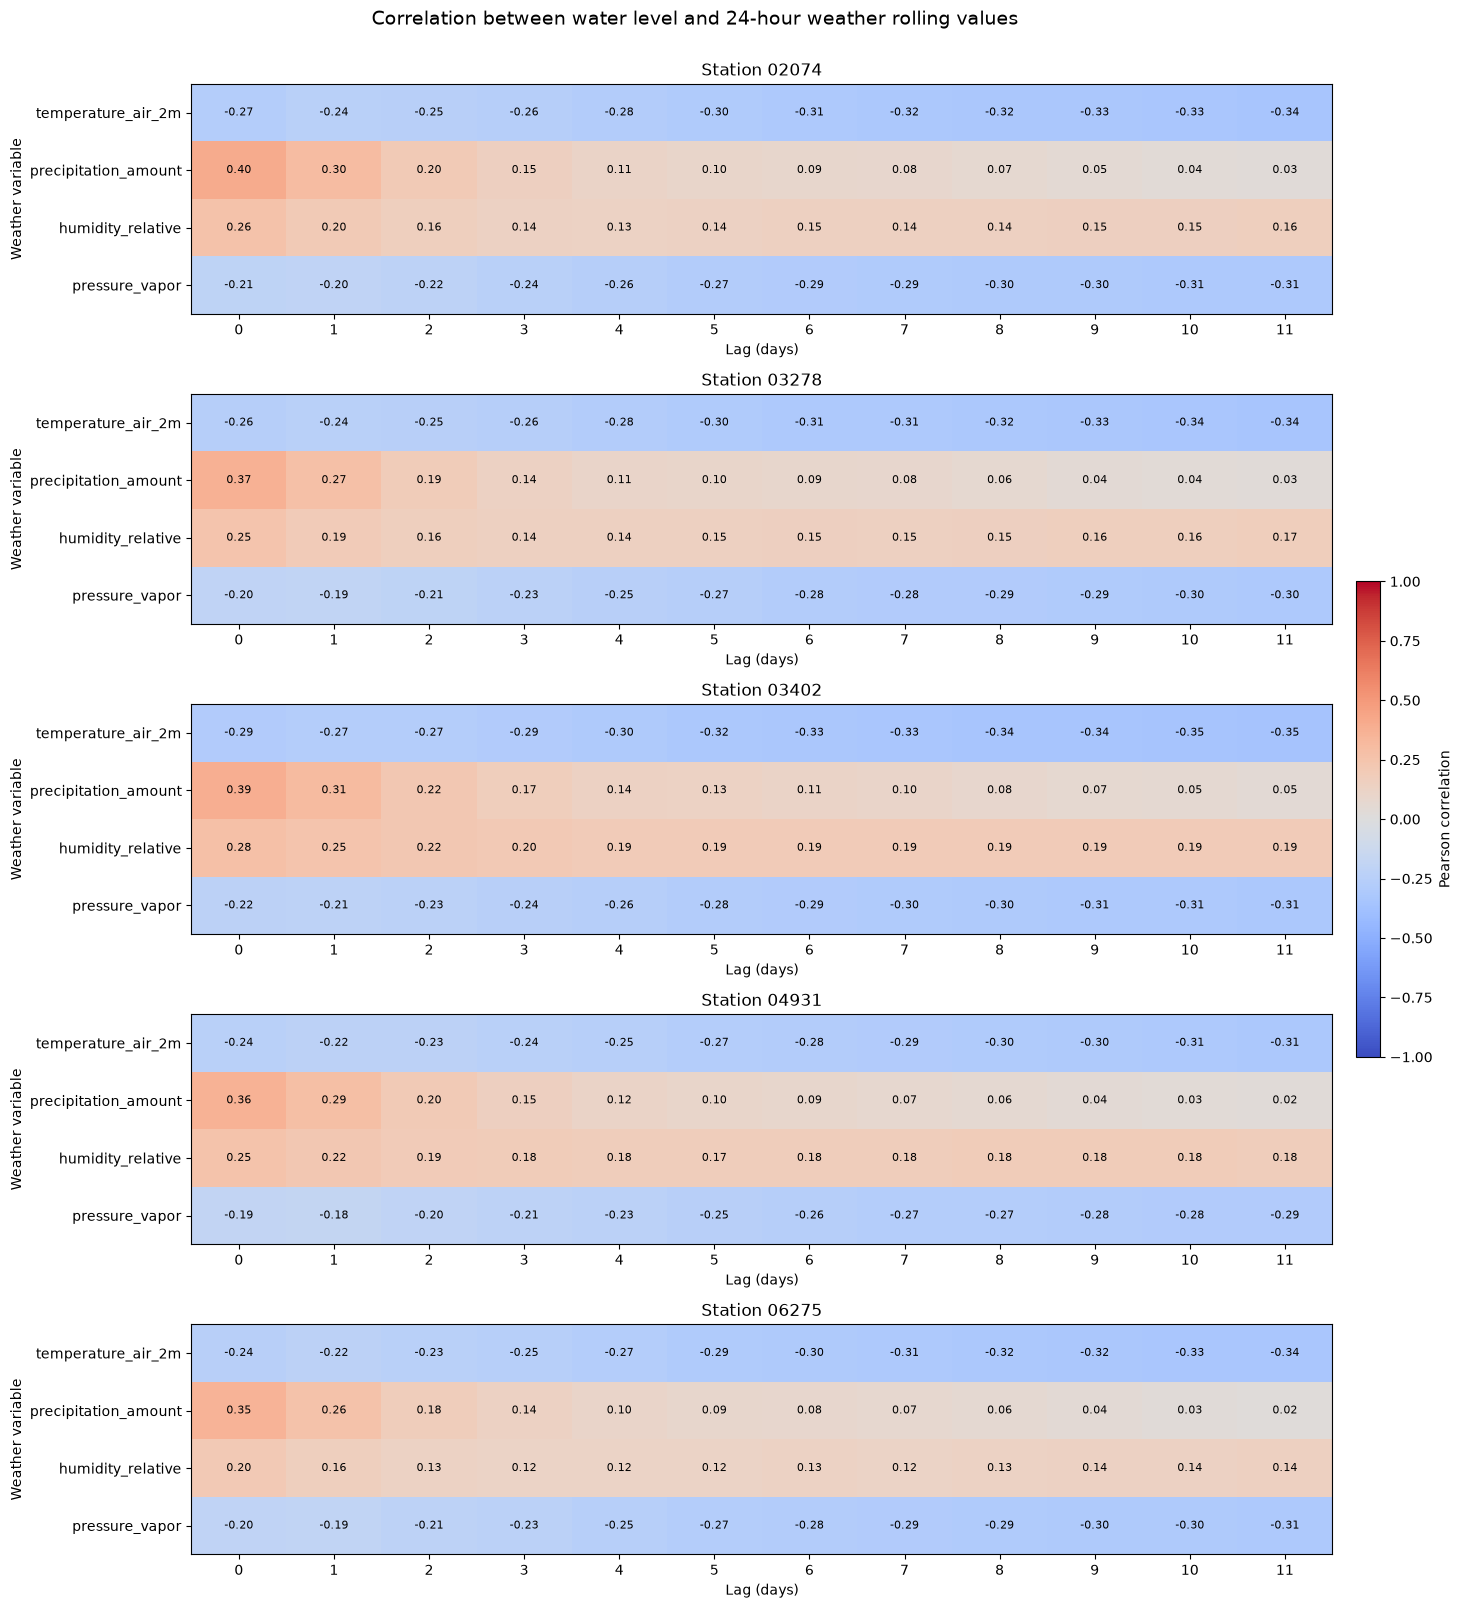

In [10]:
fig, axes = plt.subplots(
    len(station_ids), 1,
    figsize=(14, 3.2 * len(station_ids)),
    squeeze=False,
)

for axis, station_id in zip(axes[:, 0], station_ids):
    station_data = correlations[correlations["station_id"] == station_id]
    matrix = station_data.pivot(index="variable", columns="lag_days", values="correlation")
    matrix = matrix.reindex(index=variables, columns=range(12))

    image = axis.imshow(matrix, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    axis.set_title(f"Station {station_id}")
    axis.set_xlabel("Lag (days)")
    axis.set_ylabel("Weather variable")
    axis.set_xticks(range(12), labels=range(12))
    axis.set_yticks(range(len(variables)), labels=variables)

    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = matrix.iloc[row, column]
            if pd.notna(value):
                axis.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8)

fig.suptitle("Correlation between water level and 24-hour weather rolling values", y=1.002, fontsize=14)
fig.tight_layout()
fig.colorbar(image, ax=axes[:, 0], orientation="vertical", fraction=0.02, pad=0.02, label="Pearson correlation")
fig.savefig(OUT_DIR / "daily_weather_correlations_heatmaps_by_station.png", dpi=180, bbox_inches="tight")
plt.show()